# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [223]:
# importar librerías

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [224]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')#completa el código
usage = pd.read_csv('/datasets/usage.csv')#completa el código

In [225]:
# mostrar las primeras 5 filas de plans
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [226]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [227]:

usage.head()# mostrar las primeras 5 filas de usage

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [228]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage",usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [229]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [230]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [231]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [232]:

# cantidad de nulos para users
print('Valores nulos para users')
print(users.isna().sum())
print()
print('Proporción de valores nulos para users')
print(users.isna().mean())


Valores nulos para users
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de valores nulos para users
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [233]:
# cantidad de nulos para usage
print('Valores nulos para usage')
print(usage.isna().sum())
print()
print('Proporción de valores nulos para usage')
print(usage.isna().mean())


Valores nulos para usage
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de valores nulos para usage
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64




✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
  * USERS: City con una proporción del 11,7% y Churn_date con una proporción del 88,3%

  * USAGE: Date con 0.12%, duration con 55.2% y length 44.7%
- Indica qué harías: ¿imputar, eliminar, ignorar?
  * USERS:
    - City , recomiendo investigar la causa de los datos faltantes para decidir si imputar o eliminar.
    - Churn_date, aunque la proporción es muy alto, no aplico la regla general porque las fechas faltantes
      tienen en realidad el significado de los clientes activos. Recomiendo aplicar un sentinel y crear una
      nueva columna
      
   * USAGE:
     - Date, ignoraremos los valores faltantes de date.
     - Duration y Lenght, se debe evaluar que tipo de uso se está haciendo con la línea porque duration es en tiempo para las llamdas y lenght hace referencia a la longitud del texto por ende cuando uno está en llamada debe aparecer NA en lenght y viceversa 
       
      


### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [234]:

# explorar columnas numéricas de users
users['user_id'].describe()



count     4000.000000
mean     11999.500000
std       1154.844867
min      10000.000000
25%      10999.750000
50%      11999.500000
75%      12999.250000
max      13999.000000
Name: user_id, dtype: float64

In [235]:
users.duplicated(subset='user_id').sum()


0

In [236]:
users['age'].describe()

count    4000.000000
mean       33.739750
std       123.232257
min      -999.000000
25%        32.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

- La columna `user_id` no tiene sentinels, los valores ecnotrados son correctos el ID va desde 10000 hasta 13999, ahí están los 4000 registros contados
- La columna `age` presenta sentinels en las edades mínimas , y se debe evaluar si eliminar o imputar las edades.

In [237]:
# explorar columnas numéricas de usage

In [238]:

usage['id'].describe()

count    40000.00000
mean     20000.50000
std      11547.14972
min          1.00000
25%      10000.75000
50%      20000.50000
75%      30000.25000
max      40000.00000
Name: id, dtype: float64

In [239]:
usage['id'].duplicated().sum()

0

In [240]:
usage['user_id'].describe()

count    40000.000000
mean     12002.405975
std       1157.279564
min      10000.000000
25%      10996.000000
50%      12013.000000
75%      13005.000000
max      13999.000000
Name: user_id, dtype: float64

- Las columna `id` no tiene datos duplicados. Los identificadores van del 1 al 40000, con una secuencia consecutiva que coincide con la cantidad de registros del dataset. Por tanto, no se identifican valores inválidos ni sentinels en esta columna.
- La columna `user_id` presenta duplicados esperados, ya que cada usuario puede generar múltiples registros de llamadas y mensajes. Los valores están dentro del rango de los 4000 usuarios registrados, sin sentinels evidentes.

In [241]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(col)
    print(users[col].describe())
    print()
for col in columnas_user:
    print(col)
    print(users[col].value_counts(dropna=False))
    print()
 


city
count       3531
unique         7
top       Bogotá
freq         808
Name: city, dtype: object

plan
count       4000
unique         2
top       Basico
freq        2595
Name: plan, dtype: object

city
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

plan
Basico     2595
Premium    1405
Name: plan, dtype: int64



- La columna `city` tiene valores ausentes y tiene un sentinel con signo de ? por ende se tratará mas adelante
- La columna `plan` no tiene valores ausentes y no tiene sentinels.

In [242]:
# explorar columna categórica de usage
usage['type'].describe()


count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

In [243]:
usage['type'].value_counts()# completa el código

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` no tiene valores ausentes ni sentinels.


---

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
  La edad , y la ciudad 
- ¿Qué acción tomarías?
  
  En la edad se reemplazará por la mediana para evitar la influencia de valores extremos, mientras que en la ciudad se reemplazarán por NaN para tratarlos como datos faltantes y evitar introducir sesgos mediante una imputación injustificada.


### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.

- Identifica fechas imposibles (ej. años futuros o negativos).


Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [244]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] =pd.to_datetime(users['reg_date'])


In [245]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date']) # completa el código

In [246]:
# Revisar los años presentes en `reg_date` de users

users['año'] = users['reg_date'].dt.year
users['año'].unique()
users['año'].value_counts(dropna=False)


2024    1330
2023    1316
2022    1314
2026      40
Name: año, dtype: int64

In [247]:
(users['año']==2026).sum()/len(users)

0.01

En `reg_date`, hay cuatro años diferentes , por lo tanto es importante filtrar para no trabajar con 2026 que es un año imposible

In [248]:


# Revisar los años presentes en `date` de usage
usage['año'] = usage['date'].dt.year
usage['año'].value_counts(dropna=False)





2024.0    39950
NaN          50
Name: año, dtype: int64

En `date`, se identificaron registros del año 2024 y valores nulos.
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
  Si aparecen años imposibles el 2026 aún no ha transcurrido.
  Por el lado de años viejos no se reportan años muy viejos, el año más antiguo es 2022.

  Para el año de usage hay 50 nulos por lo que los ignoraremos.
  
- ¿Qué harías con ellas?
  COn el 2026 eliminaría las columnas porque es un porcentaje muy bajo (1%), y no tengo forma   confiable de "corregir" esos años (no sé cuál sería el año correcto real).

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [249]:
# Reemplazar -999 por la mediana de age
print('Total sentinels')
print((users['age']==-999).sum())
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999,age_mediana)

# Verificar cambios
users['age'].describe()

Total sentinels
55


count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [250]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)
# Verificar cambios
users['city'].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [251]:

# Marcar fechas futuras como NA para reg_date

users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT
# Verificar cambios

users['reg_date'].dt.year.value_counts(dropna=False)






2024.0    1330
2023.0    1316
2022.0    1314
NaN         40
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [252]:
# Verificación MAR en usage (Missing At Random) para length
print('length')
usage['length'].isna().groupby(usage['type']).mean()

length


type
call    0.99933
text    0.00000
Name: length, dtype: float64

In [253]:

# Verificación MAR en usage (Missing At Random) para duration
print('duration')
usage['duration'].isna().groupby(usage['type']).mean()


duration


type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [254]:

# Verificación MAR en usage (Missing At Random) para duration
usage[['duration', 'length']].isna().groupby(usage['type']).mean()


,duration,length
type,,
call,0.000000,0.99933
text,0.999276,0.00000


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

Los valores nulos en duration y length dependen de la columna type. Las llamadas presentan valores nulos en length, mientras que los mensajes de texto presentan valores nulos en duration. Estos valores son esperados según la naturaleza de cada registro, por lo que se dejarán como nulos, ya que no representan datos faltantes que deban imputarse.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [255]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage[["is_text","is_call",'duration']].groupby(usage['user_id']).sum().reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [256]:

# Renombrar columnas
usage_agg = usage_agg.rename(columns={'is_text': 'cant_mensajes','is_call':'cant_llamadas','duration': 'cant_minutos_llamada'})

# observar resultado
usage_agg.head(3)


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [257]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(users,usage_agg, on='user_id',how='left')
user_profile.head(5)


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,año,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,2022,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,2022,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,2022,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,2022,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,2022,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [258]:
# Resumen estadístico de las columnas numéricas
user_profile[user_profile['año']==2024].describe()

,user_id,age,año,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,1330.000000,1330.000000,1330.0,1330.000000,1330.000000,1330.000000
mean,13332.699248,48.414286,2024.0,5.500000,4.557143,24.126669
std,384.969999,17.963443,0.0,2.382293,2.140329,19.458620
min,12666.000000,18.000000,2024.0,0.000000,0.000000,0.000000
25%,12999.250000,33.000000,2024.0,4.000000,3.000000,11.332500
50%,13333.500000,48.000000,2024.0,5.000000,4.000000,20.325000
75%,13665.750000,64.000000,2024.0,7.000000,6.000000,32.542500
max,13999.000000,79.000000,2024.0,16.000000,13.000000,155.690000


In [259]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True)

Basico     0.64875
Premium    0.35125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

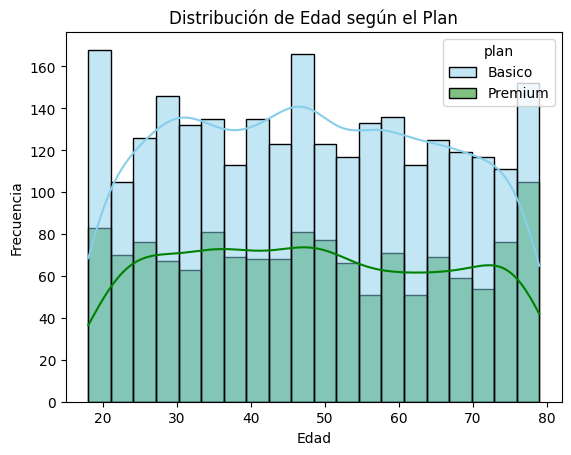

In [260]:
# Histograma para visualizar la edad (age)


sns.histplot(
    data=user_profile,
    x='age',
    hue='plan',
    bins=20,
    palette=['skyblue', 'green'],
    kde=True
)

plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.title('Distribución de Edad según el Plan')
plt.show()


💡Insights: 
- “En el plan Básico, hay dos grupos de edades más numerosos, estos se encuentran entre los más jovenes (18-25 años) y entre las pesronas de 45 y 50 años, mientras que en el Premium el grupo más numeroso es el de 75 a 80 años. Sin embargo, en ambos planes la distribución de edades es bastante homogénea, por lo que la edad el servicio de telecomunicaciones tiene una base muy diversa. Lo que sí destaca es que el plan Básico tiene aproximadamente el doble de usuarios que el Premium en casi todos los rangos de edad.”
  
- Distribución no es normal ni sesgada, si bien la media y mediana de la edad son casi iguales, las edades de los 20 y 79 años no permiten que se frome una campana para afrimar que es una distribución  normal. 

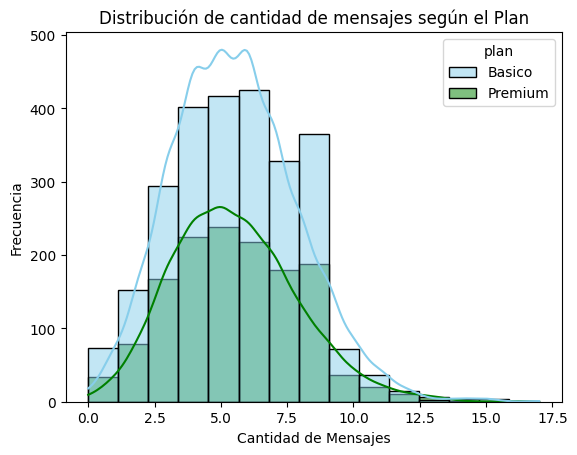

In [261]:
# Histograma para visualizar la cant_mensajes

sns.histplot(
    data=user_profile,
    x='cant_mensajes',
    hue='plan',
    bins=15,
    palette=['skyblue', 'green'],
    kde=True
)

plt.xlabel('Cantidad de Mensajes')
plt.ylabel('Frecuencia')
plt.title('Distribución de cantidad de mensajes según el Plan')
plt.show()


💡Insights: “El comportamiento de uso de mensajes es similar en ambos planes: la mayoría de los clientes envía entre 3 y 9 mensajes, con un pico alrededor de 5-6. Las diferencias en frecuencia se deben principalmente al mayor número de clientes en el plan Básico, no a un mayor uso.”
- La distribución tiene un ligero sesgo hacia la derecha.
  

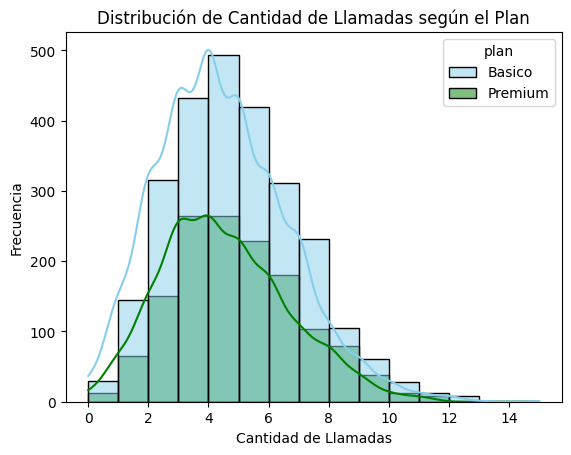

In [262]:
# Histograma para visualizar la cant_llamadas
sns.histplot(
    data=user_profile,
    x='cant_llamadas',
    hue='plan',
    bins=15,
    palette=['skyblue', 'green'],
    kde=True
)

plt.xlabel('Cantidad de Llamadas')
plt.ylabel('Frecuencia')
plt.title('Distribución de Cantidad de Llamadas según el Plan')
plt.show()


💡Insights: La mayoría de los clientes realiza entre 2 y 7 llamadas, con un pico en 4, mientras que un grupo reducido tiene un uso mucho más alto (hasta 13-15 llamadas). La forma de la distribución es muy similar entre Básico y Premium; las diferencias en frecuencia reflejan el mayor número de clientes en el plan Básico, no un mayor uso.
- Distribución ligeramente sesgada a la derecha.

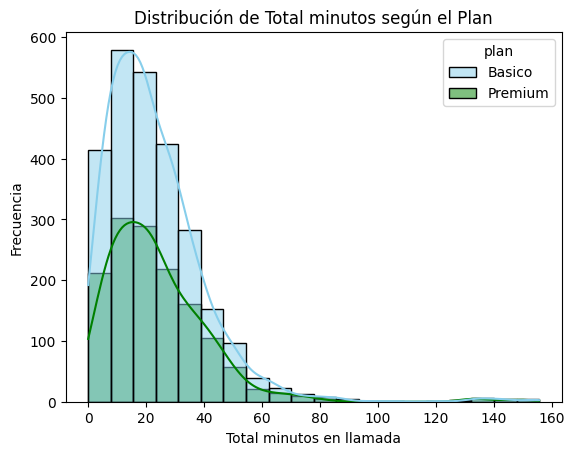

In [263]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(
    data=user_profile,
    x='cant_minutos_llamada',
    hue='plan',
    bins=20,
    palette=['skyblue', 'green'],
    kde=True
)

plt.xlabel('Total minutos en llamada')
plt.ylabel('Frecuencia')
plt.title('Distribución de Total minutos según el Plan')
plt.show()


💡Insights: 
- La distribución del total de minutos presenta un fuerte sesgo a la derecha en ambos planes. La mayoría de los clientes usa entre 0 y 40 minutos, con un pico entre 10 y 20, mientras que un grupo muy reducido supera los 100 minutos, llegando hasta unos 150. El comportamiento es similar entre Básico y Premium.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

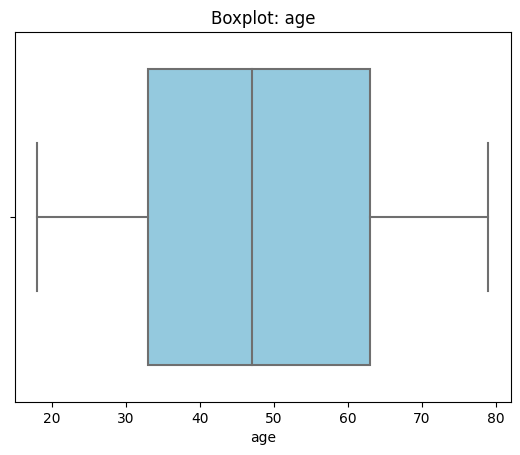

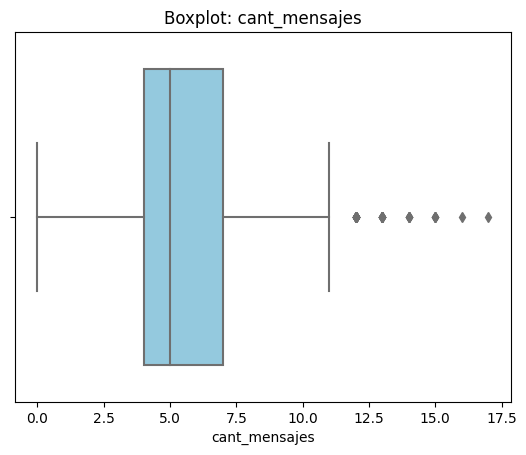

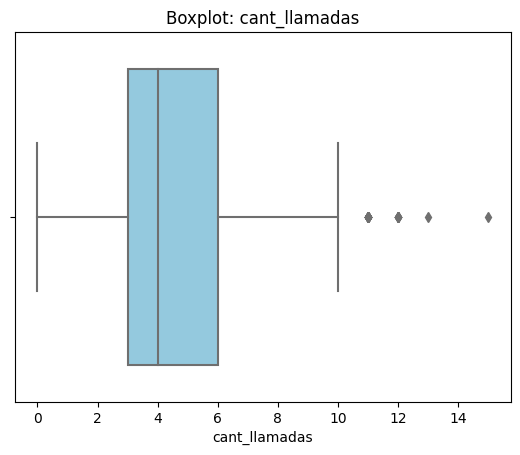

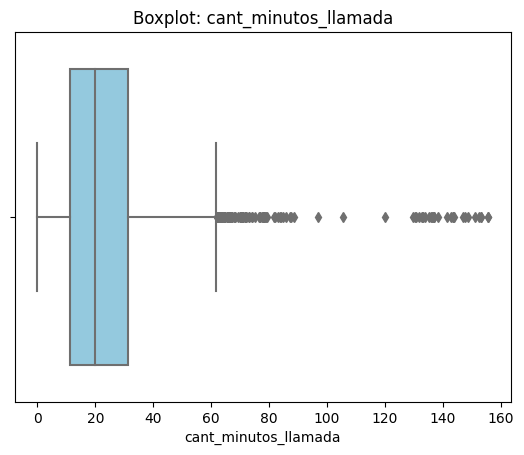

In [264]:

# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.xlabel(col)
    plt.title(f'Boxplot: {col}')
    plt.show()



💡Insights: 
- Age: no presenta outliers
- cant_mensajes: presenta pocos outliers.
- cant_llamadas: presenta pocos outliers.
- cant_minutos_llamada: presenta una gran cantidad de outliers.

In [265]:
# Calcular límites con el método IQR
columnas_limites = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
for col in columnas_limites:
    print(f'{col}')
    Q1= user_profile[col].quantile(0.25)
    print(f'Q1 de {col}: {Q1}')
    Q2= user_profile[col].quantile(0.5)
    print(f'Q2 de {col}: {Q2}')
    Q3= user_profile[col].quantile(0.75)
    print(f'Q3 de {col}: {Q3}')

    IQR = Q3-Q1
    print(f'IQR de {col}: {IQR}')

    lower = Q1 - 1.5 * IQR
    print('Límite inferior: ', lower)

    upper = Q3 + 1.5 * IQR
    print('Límite superior: ', upper)
    print()

age
Q1 de age: 33.0
Q2 de age: 47.0
Q3 de age: 63.0
IQR de age: 30.0
Límite inferior:  -12.0
Límite superior:  108.0

cant_mensajes
Q1 de cant_mensajes: 4.0
Q2 de cant_mensajes: 5.0
Q3 de cant_mensajes: 7.0
IQR de cant_mensajes: 3.0
Límite inferior:  -0.5
Límite superior:  11.5

cant_llamadas
Q1 de cant_llamadas: 3.0
Q2 de cant_llamadas: 4.0
Q3 de cant_llamadas: 6.0
IQR de cant_llamadas: 3.0
Límite inferior:  -1.5
Límite superior:  10.5

cant_minutos_llamada
Q1 de cant_minutos_llamada: 11.12
Q2 de cant_minutos_llamada: 19.78
Q3 de cant_minutos_llamada: 31.415
IQR de cant_minutos_llamada: 20.295
Límite inferior:  -19.322500000000005
Límite superior:  61.8575



In [266]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.122250,5.524381,4.478120,23.317054
std,17.690408,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,47.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [267]:
(user_profile['cant_mensajes'] > 11.5).mean()

0.0115

In [268]:
(user_profile['cant_llamadas'] > 10.5).mean()

0.0075

In [269]:
atipicos = user_profile[user_profile['cant_minutos_llamada'] > 61.8575].copy()
atipicos['min_por_llamada'] = atipicos['cant_minutos_llamada'] / atipicos['cant_llamadas']
print(atipicos['min_por_llamada'].describe())

count    109.000000
mean      16.569223
std       15.829660
min        5.207333
25%        8.195000
50%       10.403333
75%       20.567143
max      120.000000
Name: min_por_llamada, dtype: float64


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
- Se identificaron valores atípicos en cant_mensajes (entre 12 y 17 mensajes, por encima del límite superior de 11.5). Se decidió mantenerlos porque corresponden a comportamientos de uso alto plausibles, no a errores de registro, y representan una proporción pequeña de los datos.

- cant_llamadas: mantener o no outliers, porqué?
- Se identificaron valores atípicos en cant_llamadas (entre 11 y 15 llamadas, por encima del límite superior de 10.5). Se decidió mantenerlos porque corresponden a comportamientos de uso alto plausibles y no a errores de registro. Representan una proporción pequeña de los datos.
- cant_minutos_llamada: mantener o no outliers, porqué?
- Se identificaron 109 clientes con minutos totales por encima del límite superior (61.86). Al dividir por su cantidad de llamadas, la mediana es de 10.4 minutos por llamada, lo cual es consistente con un uso intensivo y no con errores de registro. Se mantuvieron en el análisis. Un caso aislado con 120 minutos por llamada se revisó y se conservó por ser plausible.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [270]:


# Crear columna grupo_uso
def classify_uso(row):
    llamadas=row['cant_llamadas']
    mensajes=row['cant_mensajes']

    if llamadas < 5 and mensajes < 5:
        return 'Bajo uso'
        
    elif llamadas < 10 and mensajes < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(classify_uso, axis=1)

    


In [271]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,año,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,2022,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,2022,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,2022,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,2022,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,2022,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [272]:

# Crear columna grupo_edad
def classify_edad(row):
    edad=row['age']
    

    if edad < 30:
        return 'Joven'
        
    elif edad < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile.apply(classify_edad, axis=1)


In [273]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,año,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,2022,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,2022,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,2022,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,2022,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,2022,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

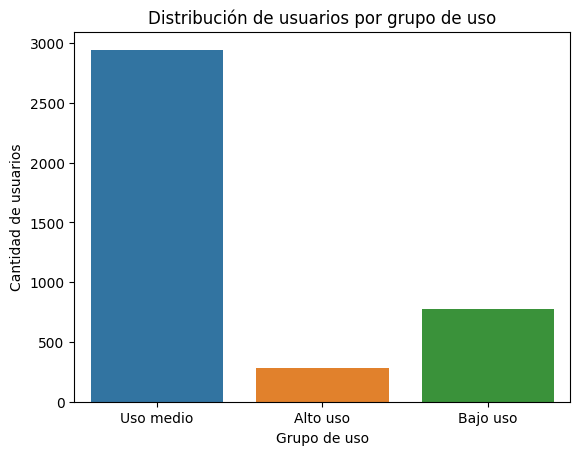

In [274]:

# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso')

plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de usuarios por grupo de uso')
plt.show()


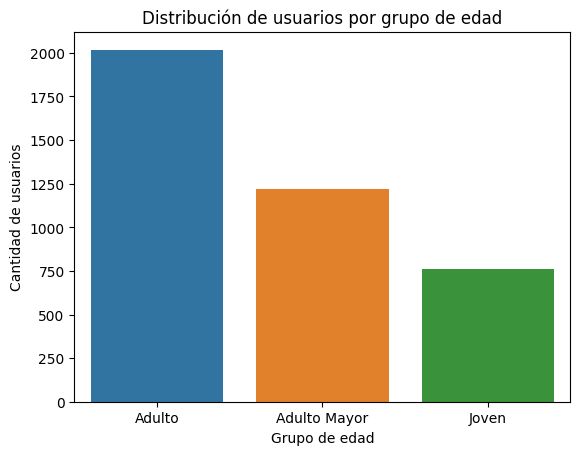

In [275]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad')

plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribución de usuarios por grupo de edad')
plt.show()

In [282]:

user_profile['grupo_uso'].groupby(user_profile['grupo_edad']).value_counts()



grupo_edad    grupo_uso
Adulto        Uso medio    1500
              Bajo uso      364
              Alto uso      154
Adulto Mayor  Uso medio     891
              Bajo uso      257
              Alto uso       74
Joven         Uso medio     552
              Bajo uso      157
              Alto uso       51
Name: grupo_uso, dtype: int64


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

- La variable "City" tenía 469 valores nulos y representaban el 11.72% total de valores nulos en la columna.
- La variable "Churn_date" tiene 3534 valores nulos y representan el 88.4% de los valores totales de la columna no se eliminaron ni trataron porque las fechas faltantes tienen en realidad el significado de los clientes activos.

- La variable "date" del dataframe Usage estaba como un object, por lo que se necesitó tranformarla a tipo fecha para  evaluar años antiguos o imposibles.

- La variable ¨date" del dataframe Usage tenía 50 valores nulos y representaban el el 0.13% de los datos totales de la columna. Sin embargo estos valores se dejaron como nulos puesto que no se puede conocer correctamente cuales serían las fechas correctas y no se eliminan porque son muy pocos datos.

- La columna "age" tenía 55 sentinels con un valores de -999 el cual fue reemplazado por la mediana.

- La columna "City" tenía 96 sentinels con '?', los valores se trataron como nulos.

- Los valores nulos en duration y length dependen de la columna type. Las llamadas presentan valores nulos en length, mientras que los mensajes de texto presentan valores nulos en duration. Estos valores son esperados según la naturaleza de cada registro, por lo que se dejarán como nulos, ya que no representan datos faltantes que deban imputarse.


🔍 **Segmentos por Edad**
-los adultos son el grupo más numeroso (aprox. 2.020 usuarios, ~50%), seguidos por los adultos mayores (~1.220, ~30%) y los jóvenes (~760, ~19%). Es decir, el plan está más afiliado a población adulta, mientras que los jóvenes tienen la menor presencia.


📊 **Segmentos por Nivel de Uso**
- La gran mayoría de los usuarios (aprox. 2.950 de 4.000, cerca del 74%) se ubica en el grupo de uso medio. Le sigue el grupo de bajo uso (aprox. 780 usuarios, ~19%) y, por último, el de alto uso, con apenas ~280 usuarios (~7%).

Para ConnectaTel los segementos se pueden calsificar en tres categorías:
Valor por tamaño actual:

Adultos con uso medio (1.500): más de un tercio de la base, con ingresos estables y recurrentes. Son el núcleo del negocio.

Valor por potencial:

Adultos con alto uso (154): son pocos, pero concentran el 55% de los usuarios de alto consumo y son los mejores candidatos para planes superiores o servicios adicionales.
Jóvenes (760): hoy son el grupo más pequeño, pero tienen potencial de crecimiento a largo plazo si se logra atraer a más clientes de esa edad.

Segmentos en riesgo:

Usuarios de bajo uso, especialmente adultos mayores (257) y jóvenes (157): pueden sentir que no aprovechan lo que pagan, lo que aumenta el riesgo de abandono. Son una oportunidad para campañas que incentiven el consumo.

 **Outliers**
 - Mensajes y llamadas: atípicos leves (12-17 mensajes, 11-15 llamadas), plausibles para clientes activos.
- Minutos de llamada: el caso más marcado. 109 clientes superan los 61.86 minutos, con valores de hasta ~155. Su mediana es de 10.4 min por llamada, así que reflejan uso intensivo real, no errores. - Un caso aislado de 120 min por llamada conviene revisarlo.

Implicaciones para el negocio

- Existe un segmento pequeño de clientes de alto consumo que concentra buena parte del uso.
Oportunidad de migrar a Premium a los clientes Básico más intensivos, y de asegurar que Premium cubra bien a sus necesidades y la des familiares.
Estos clientes impactan los costos y su pérdida sería costosa, por lo que conviene monitorear su retención.
💡 **Recomendaciones**
1. Fortalecer el plan Premium: identificar clientes del plan Básico con alto consumo y ofrecerles beneficios adicionales, como más minutos, mensajes y descuentos por fidelidad.

2. Incentivar a los usuarios de bajo consumo: ofrecer planes económicos y flexibles, especialmente para adultos mayores y jóvenes que no aprovechan completamente los servicios actuales.

3. Atraer nuevos clientes jóvenes: desarrollar planes con precios competitivos, beneficios digitales y opciones adaptables a sus necesidades.

4. Mejorar la retención: monitorear las disminuciones en el consumo y desarrollar campañas de fidelización para prevenir el abandono de clientes.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`